# Robustness Analysis

This notebook evaluates the robustness of three binary classification models for heart disease prediction: Logistic Regression, Random Forest, and a Multi-Layer Perceptron (MLP).

Each model is evaluated across five stratified cross-validation folds created with a fixed random seed (`40`).

The main objective is to maximize a weighted score combining recall and precision, with a greater weight assigned to recall.

In [ ]:
# Standard library
import sys

sys.path.append("..")

# Third-party libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.metrics import precision_recall_curve
from sklearn.model_selection import StratifiedKFold

# Project modules
from src.data_cleaning import load_data
from src.experiment import run_experiment

## Experimental Setup

Run the same training, threshold selection, and evaluation procedure across five stratified folds. A fixed random seed (`40`) makes the fold assignment reproducible and matches the seed used in the model comparison notebook.

For each fold, approximately 20% of the data is held out for testing. The remaining 80% is split into training and validation sets. Logistic Regression and Random Forest hyperparameters are selected by cross-validation within the training subset. The validation set selects the MLP checkpoint using validation loss and is used to select each model's threshold by maximizing a weighted score combining recall and precision, with a weight of 0.8 assigned to recall. Each model is evaluated on the held-out test fold using its validation-selected threshold.

In [ ]:
RANDOM_STATE = 40
N_SPLITS = 5

_, y = load_data()

cross_validation = StratifiedKFold(
    n_splits=N_SPLITS,
    shuffle=True,
    random_state=RANDOM_STATE
)

all_results = []

for fold, (train_indices, test_indices) in enumerate(
    cross_validation.split(np.zeros(len(y)), y),
    start=1
):
    print(f"Fold {fold}/{N_SPLITS}")
    results = run_experiment(
        RANDOM_STATE,
        train_indices,
        test_indices
    )
    all_results.append(results)

Fold 1/5
Fold 2/5
Fold 3/5
Fold 4/5
Fold 5/5


## Results Summary

Compute the mean and standard deviation of each evaluation metric across the five test folds for each model. The fold-level results can also be inspected in `all_results`.

The fold scores are related because their training sets overlap; the summary describes performance across this cross-validation procedure.

In [ ]:
models = [
    "Logistic Regression",
    "Random Forest",
    "MLP"
]

metrics_summary = {}

for model in models:
    metrics = pd.DataFrame([
        result[model]["metrics"] for result in all_results
    ])

    metrics_summary[model] = {
        metric: (
            f"{metrics[metric].mean():.4f} "
            f"± {metrics[metric].std(ddof=1):.4f}"
        )
        for metric in metrics.columns
    }

summary_table = pd.DataFrame.from_dict(
    metrics_summary,
    orient="index"
)

summary_table.index.name = "Model"

display(summary_table)

,Threshold,Loss,Accuracy,Precision,Recall,F1-score,Average Precision
Model,,,,,,,
Logistic Regression,0.2655 ± 0.1866,0.4080 ± 0.0523,0.7236 ± 0.0992,0.6668 ± 0.1471,0.9198 ± 0.0825,0.7607 ± 0.0641,0.8970 ± 0.0371
Random Forest,0.2706 ± 0.1564,0.4165 ± 0.0630,0.7103 ± 0.1037,0.6488 ± 0.1215,0.9127 ± 0.0822,0.7493 ± 0.0664,0.8899 ± 0.0363
MLP,0.2970 ± 0.2631,0.4267 ± 0.0881,0.7303 ± 0.0934,0.6996 ± 0.1769,0.8685 ± 0.1380,0.7535 ± 0.0605,0.8894 ± 0.0404


## Precision-Recall Curve Comparison

Compare the mean precision-recall curves across the five test folds for each model.

The curves are interpolated onto a common recall grid before averaging, allowing the models' precision-recall trade-offs to be compared across the folds.

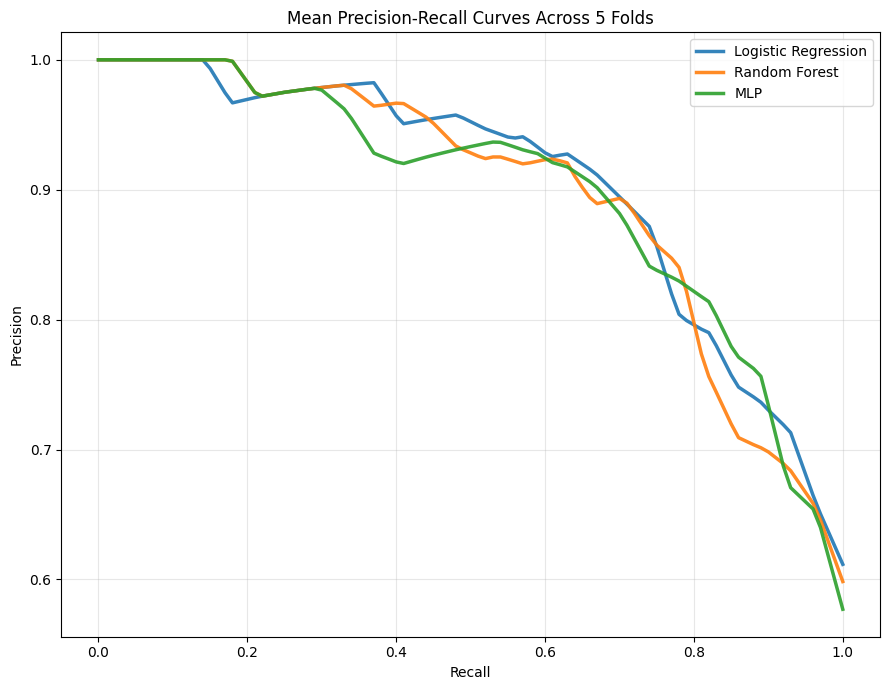

In [ ]:
recall_grid = np.linspace(0, 1, 101)

plt.figure(figsize=(9, 7))

for model in models:
    interpolated_precisions = []

    for result in all_results:
        y_true = result[model]["y_true"]
        y_proba = result[model]["y_proba"]

        precision, recall, _ = precision_recall_curve(
            y_true, y_proba
        )

        recall_ascending = recall[::-1]
        precision_ascending = precision[::-1]

        recall_unique, indices = np.unique(
            recall_ascending, return_index=True
        )
        precision_unique = precision_ascending[indices]

        interpolated_precision = np.interp(
            recall_grid,
            recall_unique,
            precision_unique
        )

        interpolated_precisions.append(interpolated_precision)

    interpolated_precisions = np.array(interpolated_precisions)
    mean_precision = interpolated_precisions.mean(axis=0)

    plt.plot(
        recall_grid,
        mean_precision,
        label=model,
        linewidth=2.5,
        alpha=0.9
    )

plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Mean Precision-Recall Curves Across 5 Folds")
plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

## Results Analysis

The five-fold results show broadly similar performance across the three models. Logistic Regression has the highest mean Average Precision (0.8970 +/- 0.0371), with Random Forest and the MLP close behind (0.8899 +/- 0.0363 and 0.8894 +/- 0.0404, respectively). The precision-recall curves also overlap substantially, so the differences should be interpreted cautiously.

With thresholds selected on each fold validation set, Logistic Regression and Random Forest achieve similar mean recall (0.9198 +/- 0.0825 and 0.9127 +/- 0.0822). The MLP has higher mean precision (0.6996 +/- 0.1769), but lower and more variable recall (0.8685 +/- 0.1380). This shows different trade-offs among the three models: Logistic Regression has a small advantage in recall and Average Precision, Random Forest has similar recall, and the MLP has higher mean precision. The results do not establish a clear overall winner.

These results compare the models under the current data splits and threshold-selection procedure. The fold scores are related because their training sets overlap, and the small dataset limits how confidently the differences can be generalized.